In [1]:
import numpy as np

docs = ['go india',
		'india india',
		'hip hip hurray',
		'jeetega bhai jeetega india jeetega',
		'bharat mata ki jai',
		'kohli kohli',
		'sachin sachin',
		'dhoni dhoni',
		'modi ji ki jai',
		'inquilab zindabad']

In [2]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer(oov_token = '<nothing>')

### Text to Numbers

In [3]:
tokenizer.fit_on_texts(docs)

## Mini Project Using Integer Encoding

In [21]:
from keras.datasets import imdb
from keras import Sequential
from keras.layers import Input, Dense, SimpleRNN, Flatten

In [22]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    path="E:/Deep Learning/DL/RNN/Sentiment Analysis/imdb.npz"
)

In [23]:
x_train.shape

(25000,)

In [24]:
x_train = pad_sequences(x_train, padding='post', maxlen=50)
x_test = pad_sequences(x_test, padding='post', maxlen=50)

In [30]:
model = Sequential()


model.add(Input(shape=(50, 1)))
model.add(SimpleRNN(32, return_sequences=False))
model.add(Dense(1, activation='sigmoid'))

In [31]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_6 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(optimizer = 'adam', loss='binary_crossentropy', metrics=['accuracy'])

### Integer-Encoding

In [33]:
history = model.fit(x_train, y_train, epochs = 10, validation_data = (x_test, y_test))

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.5046 - loss: 0.7093 - val_accuracy: 0.5036 - val_loss: 0.6941
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.5063 - loss: 0.6931 - val_accuracy: 0.5054 - val_loss: 0.6937
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.4980 - loss: 0.6932 - val_accuracy: 0.5026 - val_loss: 0.6958
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.5046 - loss: 0.6934 - val_accuracy: 0.5067 - val_loss: 0.6935
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5092 - loss: 0.6927 - val_accuracy: 0.5063 - val_loss: 0.6935
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5045 - loss: 0.6920 - val_accuracy: 0.5038 - val_loss: 0.6953
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.5096 - loss: 0.6925 - val_accuracy: 0.5044 - val_loss: 0.6943
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.5039 - loss: 0.6921 - v

### Integer-Encoding Performance

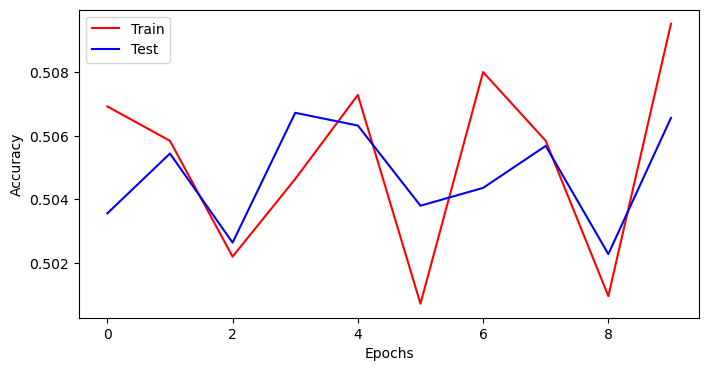

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train', color='Red')
plt.plot(history.history['val_accuracy'], label='Test', color='blue')

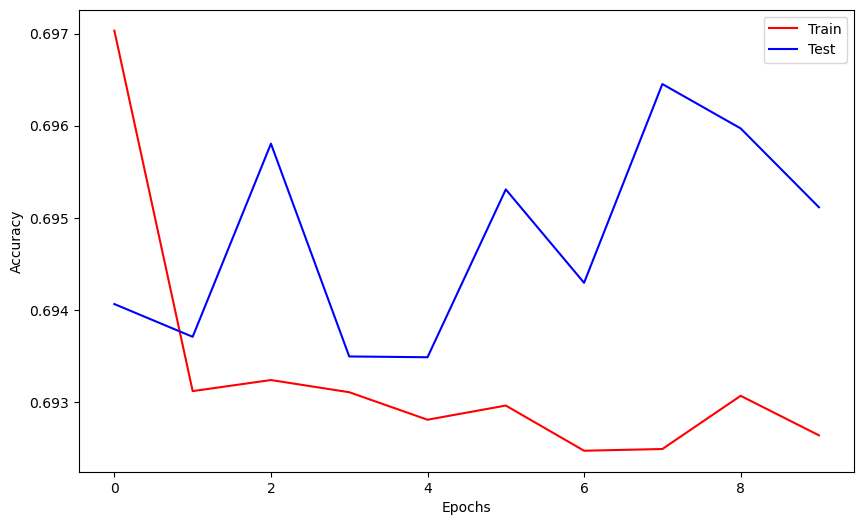

In [35]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Train', color='Red')
plt.plot(history.history['val_loss'], label='Test', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()